# UCS420 Assignment 7 — NLP-I: Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170346
NAME = "Amatya Simba"

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170346   Name: Amatya Simba   Fingerprint: 80EC6839   Tickets: 13

Ticket_ID                                                                        Ticket_Text
      T01           Python keeps asking for login during the lab. I don't know what changed.
      T02                           The laptop is running slowly. I don't know what changed.
      T03                        The student portal is showing an error. Can you check this?
      T04           Python crashes while opening after the latest update. Please resolve it.
      T05                     The student portal keeps asking for login. Can you check this?
      T06                                             Only 2 of 30 PCs boot after 3.5 hours.
      T07  Student portal is showing an error while uploading the file. It worked yesterday.
      T08                                                 Dr. Rao's lab PC (No. 14) is down.
      T09             I reinstalled the password on my laptop. It works on anot

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
import pandas as pd

# Run the official pipeline on every ticket
results = {tid: process_ticket(txt) for tid, txt in zip(df["Ticket_ID"], df["Ticket_Text"])}

rows = []
for tid, r in results.items():
    # sanity check: every token is exactly one of punctuation / stopword / final token
    assert len(r["tokens"]) == len(r["punct"]) + len(r["stops"]) + len(r["final"])
    rows.append({
        "Ticket_ID": tid,
        "Sentences": len(r["sentences"]),
        "Tokens": len(r["tokens"]),
        "Punctuation": len(r["punct"]),
        "Stopwords": len(r["stops"]),
        "Unique_Tokens": len(set(r["tokens"])),
        "Final_Tokens": len(r["final"]),
    })
q1 = pd.DataFrame(rows)

# TOTAL row for the count-based columns
total = {"Ticket_ID": "TOTAL"}
for col in q1.columns[1:]:
    total[col] = int(q1[col].sum())
q1 = pd.concat([q1, pd.DataFrame([total])], ignore_index=True)
print(q1.to_string(index=False))

all_tokens = [t for r in results.values() for t in r["tokens"]]
print("\nNote: the Unique_Tokens TOTAL is the sum of per-ticket unique counts.")
print("Unique tokens across the whole corpus (shared words counted once):", len(set(all_tokens)))

Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique_Tokens  Final_Tokens
      T01          2      16            2          6             15             8
      T02          2      13            2          5             12             6
      T03          2      13            2          6             13             5
      T04          2      13            2          4             12             7
      T05          2      13            2          5             13             6
      T06          1      10            1          3             10             6
      T07          2      15            2          5             14             8
      T08          2      13            4          3             12             6
      T09          2      14            2          6             12             6
      T10          1      10            2          4              9             4
      T11          2      16            2          5             14             9
      T12       

In [6]:
# Detailed view of the selected (focus) tickets
for tid in FOCUS:
    r = results[tid]
    print(f"=== {tid}: {df.loc[df.Ticket_ID == tid, 'Ticket_Text'].iloc[0]}")
    print("Sentences  :", r["sentences"])
    print("Tokens     :", r["tokens"])
    print("Punctuation:", r["punct"])
    print("Stopwords  :", r["stops"])
    print("Final      :", r["final"])
    print()

=== T03: The student portal is showing an error. Can you check this?
Sentences  : ['The student portal is showing an error.', 'Can you check this?']
Tokens     : ['the', 'student', 'portal', 'is', 'showing', 'an', 'error', '.', 'can', 'you', 'check', 'this', '?']
Punctuation: ['.', '?']
Stopwords  : ['the', 'is', 'an', 'can', 'you', 'this']
Final      : ['student', 'portal', 'showing', 'error', 'check']

=== T12: I was locked out of the lms after restarting the system. Please help.
Sentences  : ['I was locked out of the lms after restarting the system.', 'Please help.']
Tokens     : ['i', 'was', 'locked', 'out', 'of', 'the', 'lms', 'after', 'restarting', 'the', 'system', '.', 'please', 'help', '.']
Punctuation: ['.', '.']
Stopwords  : ['i', 'was', 'out', 'of', 'the', 'after', 'the']
Final      : ['locked', 'lms', 'restarting', 'system', 'please', 'help']



In [7]:
# Final tokens that are not ordinary dictionary words (contraction pieces, digits, symbols)
from collections import defaultdict
src = defaultdict(list)
for tid, r in results.items():
    for t in r["final"]:
        if not t.isalpha() or len(t) <= 2:
            src[t].append(tid)
for tok, tids in sorted(src.items()):
    print(f"{tok!r:14} <- {sorted(set(tids))}")

"'s"           <- ['T08']
'+91'          <- ['T13']
'0175-239-3201' <- ['T13']
'14'           <- ['T08']
'2'            <- ['T06']
'3.5'          <- ['T06']
'30'           <- ['T06']
'43210'        <- ['T13']
'98765'        <- ['T13']
'ca'           <- ['T11']
'dr.'          <- ['T08']
"n't"          <- ['T01', 'T02', 'T10', 'T11']
'pc'           <- ['T08']
'wi-fi'        <- ['T10']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*
Non-word final tokens in my data: **`n't`** (T01, T02, T10, T11), **`ca`** (T11), **`'s`** (T08) and **`dr.`** (T08), plus number/phone pieces such as `+91`, `98765`, `43210`, `0175-239-3201`, `2`, `30`, `3.5`, `14`.

*Where they come from:* `word_tokenize` follows Penn-Treebank rules, so it splits a contraction into a stem and a clitic: don't → `do` + `n't`, doesn't → `does` + `n't`, can't → `ca` + `n't`, and Rao's → `Rao` + `'s`. The NLTK stopword list removes `do`, `does` and `is`, but it does not contain `n't`, `ca` or `'s`, so these orphan pieces survive into the final tokens. `dr.` survives because the tokenizer keeps the abbreviation's full stop attached, so `is_punct` does not treat it as punctuation. The numeric pieces survive because they are neither punctuation nor stopwords.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [8]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

# ---------- re.findall patterns ----------
# 1. words longer than 5 letters (>= 6). The look-arounds stop contraction fragments such as
#    "couldn" (from "couldn't") from being counted as a 6-letter word.
LONG_RE = r"(?<![A-Za-z'’])[A-Za-z]{6,}(?![A-Za-z]|['’][A-Za-z])"
# 2. numbers: hex codes (0x80070005), or digits with optional . or , groups -> 95.5, 2.0.1, 1,250, 5.30 stay whole.
#    A trailing full stop is NOT swallowed because a digit must follow the "." or ",".
NUM_RE = r"\b(?:0[xX][0-9A-Fa-f]+|\d+(?:[.,]\d+)*)\b"
# 3. capitalized words: capital + lowercase letters; hyphenated parts stay together (Wi-Fi). ALL-CAPS (LMS, VPN, MATLAB) are excluded.
CAP_RE = r"\b[A-Z][a-z]+(?:-[A-Z][a-z]+)*\b"
# 4. words that begin with a vowel (whole word incl. contractions / hyphens, e.g. isn't, e-mail)
VOWEL_RE = r"(?<![\w'’-])[AEIOUaeiou][A-Za-z]*(?:['’-][A-Za-z]+)*\b"

# ---------- re.sub patterns ----------
EMAIL_RE = r"\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b"
URL_RE   = r"\b(?:https?://|www\.)\S*[\w/]"          # ends on a word char or "/", so a final "." is left alone
PHONE_RE = (r"(?:\+\d{1,3}[\s-]?)?\b\d{5}[\s-]?\d{5}\b"   # 98765 43210 / +91-98765-43210
            r"|\b0\d{2,4}-\d{3,4}-\d{4}\b")               # 0175-239-3201 (STD code, not 1023-03-021)

def extract_all(text):
    return {
        "long (>5 letters)": re.findall(LONG_RE, text),
        "numbers": re.findall(NUM_RE, text),
        "capitalized": re.findall(CAP_RE, text),
        "vowel-start": re.findall(VOWEL_RE, text),
    }

def mask(text):
    text = re.sub(EMAIL_RE, "<EMAIL>", text)   # emails first, so the domain part is not mistaken for a URL
    text = re.sub(URL_RE, "<URL>", text)
    text = re.sub(PHONE_RE, "<PHONE>", text)
    return text

# ---------- run on the generated tickets ----------
q2 = pd.DataFrame([{"Ticket_ID": tid, **extract_all(txt)} for tid, txt in zip(df.Ticket_ID, df.Ticket_Text)])
pd.set_option("display.max_colwidth", None, "display.width", 250)
print(q2.to_string(index=False))

print("\n--- re.sub on tickets (only tickets that change) ---")
for tid, txt in zip(df.Ticket_ID, df.Ticket_Text):
    if mask(txt) != txt:
        print(tid, "|", txt, "\n     ->", mask(txt))

# ---------- run on TEST_LINES ----------
print("\n--- TEST_LINES ---")
for line in TEST_LINES:
    print("LINE  :", line)
    for k, v in extract_all(line).items():
        print(f"  {k:18}", v)
    print("  masked            ", mask(line), "\n")

# ---------- checks on TEST_LINES ----------
t = [extract_all(l) for l in TEST_LINES]
assert {"95.5", "2.0.1", "1,250"} <= set(t[1]["numbers"]) and "5.30" in t[2]["numbers"]
assert mask(TEST_LINES[0]) == "Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>."
assert mask(TEST_LINES[1]).startswith("Call <PHONE>, <PHONE> or <PHONE>. Version")
assert "state-of-the-art" not in t[2]["long (>5 letters)"] and "isn't" in t[2]["vowel-start"]
print("All TEST_LINES checks passed.")

Ticket_ID                                                long (>5 letters)                             numbers      capitalized                    vowel-start
      T01                                [Python, asking, during, changed]                                  []         [Python]                    [asking, I]
      T02                               [laptop, running, slowly, changed]                                  []            [The]                        [is, I]
      T03                                       [student, portal, showing]                                  []       [The, Can]                [is, an, error]
      T04      [Python, crashes, opening, latest, update, Please, resolve]                                  [] [Python, Please]   [opening, after, update, it]
      T05                                        [student, portal, asking]                                  []       [The, Can]                       [asking]
      T06                                     

In [9]:
# How many capitalized words are capitalized only because they begin a sentence?
from nltk.tokenize import sent_tokenize
PROPER = {"Python", "Wi-Fi", "Matlab", "Dr", "Rao", "No"}   # genuine names / abbreviations (judged by hand)
initial, middle = [], []
for txt in df.Ticket_Text:
    for s in sent_tokenize(txt):
        for m in re.finditer(CAP_RE, s):
            (initial if m.start() == 0 else middle).append(m.group())
start_only = [w for w in initial if w not in PROPER]
print("capitalized words in total      :", len(initial) + len(middle))
print("  at sentence start             :", len(initial), initial)
print("  in mid-sentence               :", len(middle), middle)
print("capitalized ONLY due to sentence start:", len(start_only), start_only)

capitalized words in total      : 20
  at sentence start             : 17 ['Python', 'The', 'The', 'Can', 'Python', 'Please', 'The', 'Can', 'Only', 'Student', 'It', 'Dr', 'It', 'The', 'Please', 'Please', 'Call']
  in mid-sentence               : 3 ['Rao', 'No', 'Wi-Fi']
capitalized ONLY due to sentence start: 14 ['The', 'The', 'Can', 'Please', 'The', 'Can', 'Only', 'Student', 'It', 'It', 'The', 'Please', 'Please', 'Call']


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*
My tickets contain 20 capitalized words. 17 of them are at the start of a sentence (Python, The ×3, Can ×2, Please ×3, Only, Student, It ×2, Dr, Call, Python) and 3 are mid-sentence (Rao, No, Wi-Fi). Of the 17 sentence-initial ones, 3 are genuine names/titles (Python ×2, Dr), so **14 of the 20 (70%)** are capitalized only because they begin a sentence (e.g. The, Can, Please, Only, It, Call, and Student in T07, which is written in lowercase in the other tickets). Plain capitalization is therefore a weak signal for proper nouns. (The pattern ignores the pronoun "I" and ALL-CAPS words such as LMS, VPN.)

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [10]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

# One pattern = ordered alternation (most specific first). Only NON-capturing groups, as RegexpTokenizer requires.
TOKEN_PATTERN = "|".join([
    r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+",                      # 1 email           it.helpdesk@thapar.edu
    r"(?:https?://|www\.)\S*[\w/]",                       # 2 URL             https://lms.thapar.edu/help, www.thapar.edu/it
    r"(?:\+\d{1,3}[\s-]?)?\b\d{5}[\s-]?\d{5}\b",          # 3 mobile phone    +91 98765 43210, +91-98765-43210
    r"\b0\d{2,4}-\d{3,4}-\d{4}\b",                        # 4 landline        0175-239-3201
    r"0[xX][0-9A-Fa-f]+",                                 # 5 hex code        0x80070005
    r"\d+(?:[.,]\d+)+",                                   # 6 decimal/version 95.5, 2.0.1, 1,250, 5.30
    r"(?:[A-Za-z]\.){2,}",                                # 7 dotted abbrev.  p.m.
    r"\w+(?:[-'’]\w+)*",                                  # 8 words: isn't, Wi-Fi, state-of-the-art, 1023-03-021, plain numbers
])
_tokenizer = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    return _tokenizer.tokenize(text)

# ---- TEST_LINES ----
for line in TEST_LINES:
    print("TEXT        :", line)
    print("my_tokenize :", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line), "\n")

# ---- must-keep checks from the assignment ----
chk = my_tokenize("It isn't the Wi-Fi in the state-of-the-art lab: 95.5 and 2.0.1. Mail a@b.edu, see https://x.edu/a, call +91 98765 43210.")
for must in ["isn't", "Wi-Fi", "state-of-the-art", "95.5", "2.0.1", "a@b.edu", "https://x.edu/a", "+91 98765 43210"]:
    assert must in chk, must
print("All required tokens are preserved as single tokens.\n")

TEXT        : Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.'] 

TEXT        : Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize : ['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1,250']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.'] 

TEXT        : The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
my_tokenize : ['Th

In [11]:
# ---- compare on the tickets ----
def strip_punct(tokens):
    return [t for t in tokens if not is_punct(t)]

rows, diff_examples = [], {}
for tid, txt in zip(df.Ticket_ID, df.Ticket_Text):
    mine, nltk_t = my_tokenize(txt), word_tokenize(txt)
    nltk_nopunct = strip_punct(nltk_t)
    only_mine  = [t for t in mine if t not in nltk_t]
    only_nltk  = [t for t in nltk_nopunct if t not in mine]
    rows.append({"Ticket_ID": tid, "my_tokenize": len(mine), "word_tokenize": len(nltk_t),
                 "differs (raw)": mine != nltk_t,
                 "differs (ignoring punctuation)": mine != nltk_nopunct,
                 "only in my_tokenize": only_mine, "only in word_tokenize": only_nltk})
q3 = pd.DataFrame(rows)
print(q3.to_string(index=False))
print("\nTickets tokenized differently (raw)                    :", int(q3["differs (raw)"].sum()), "of", len(q3))
print("Tickets tokenized differently (ignoring punctuation)   :", int(q3["differs (ignoring punctuation)"].sum()), "of", len(q3))

# ---- distinct tokens that my_tokenize keeps whole but word_tokenize breaks up (TEST_LINES + tickets) ----
kept = {}
for text in TEST_LINES + list(df.Ticket_Text):
    wt = word_tokenize(text)
    for tok in my_tokenize(text):
        if tok not in wt:
            kept[tok] = [x for x in wt if x not in my_tokenize(text)]
print("\nTokens kept whole by my_tokenize but split / changed by word_tokenize:")
for tok in kept:
    print(f"  {tok!r}")

Ticket_ID  my_tokenize  word_tokenize  differs (raw)  differs (ignoring punctuation) only in my_tokenize only in word_tokenize
      T01           13             16           True                            True             [don't]             [do, n't]
      T02           10             13           True                            True             [don't]             [do, n't]
      T03           11             13           True                           False                  []                    []
      T04           11             13           True                           False                  []                    []
      T05           11             13           True                           False                  []                    []
      T06            9             10           True                           False                  []                    []
      T07           13             15           True                           False                  []       

**Differences between `my_tokenize` and `word_tokenize` (from the TEST_LINES and my tickets):**

1. **Contractions:** `isn't`, `didn't`, `don't`, `doesn't`, `can't` stay whole in `my_tokenize`; `word_tokenize` gives `is` + `n't`, `did` + `n't`, `do` + `n't`, `does` + `n't` and the odd `ca` + `n't`.
2. **Emails and URLs:** `it.helpdesk@thapar.edu` and `https://lms.thapar.edu/help` stay as single tokens in `my_tokenize`; `word_tokenize` splits the email at `@` (`it.helpdesk`, `@`, `thapar.edu`) and the URL at `://` (`https`, `:`, `//lms.thapar.edu/help`).
3. **Phone numbers:** `+91 98765 43210` is one token in `my_tokenize` but three (`+91`, `98765`, `43210`) in `word_tokenize` because of the spaces (`+91-98765-43210` and `0175-239-3201` are kept whole by both).
4. **Possessive and abbreviation:** `Rao's` stays whole in `my_tokenize` (`word_tokenize`: `Rao` + `'s`); `Dr.` becomes `Dr` in mine (the full stop is dropped) but `Dr.` in `word_tokenize`.
5. **Punctuation:** `word_tokenize` returns punctuation as separate tokens (`.`, `?`, `;`, `%`, `(`, `)`), whereas my pattern has no punctuation alternative, so they are dropped (95.5% → `95.5`).

Both tokenizers keep `Wi-Fi`, `state-of-the-art`, `95.5`, `2.0.1`, `5.30`, `p.m.` and `1,250` whole.

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*
All **13 of 13** tickets differ from `word_tokenize` in the raw output, because `word_tokenize` emits punctuation tokens and mine does not. If punctuation tokens are removed from the `word_tokenize` output first, **6 of 13** tickets are still tokenized differently: T01, T02 (don't), T08 (Dr. / Rao's), T10 (doesn't), T11 (can't) and T13 (the spaced phone number).

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [12]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from collections import Counter, defaultdict

unique_final = sorted({t for r in results.values() for t in r["final"]})
print(len(unique_final), "unique final tokens:\n", unique_final)

# Look at the words in OUR data before choosing the Regexp-stemmer suffix
for suf in ["ing", "ed", "s"]:
    print(f"\nwords ending in -{suf}:", [w for w in unique_final if w.endswith(suf) and w.isalpha()])

# Regexp stemmer suffix chosen from the data above
REGEXP_SUFFIX = 'ing$|ed$'

58 unique final tokens:
 ["'s", '+91', '0175-239-3201', '14', '2', '3.5', '30', '43210', '98765', 'another', 'asking', 'assignment', 'boot', 'ca', 'call', 'changed', 'check', 'computer', 'crashes', 'deadline', 'dr.', 'error', 'file', 'help', 'hours', 'keeps', 'know', 'lab', 'laptop', 'latest', 'lms', 'locked', 'login', "n't", 'open', 'opening', 'password', 'pc', 'pcs', 'please', 'portal', 'python', 'rao', 'reinstalled', 'resolve', 'restarting', 'running', 'showing', 'slowly', 'student', 'system', 'update', 'uploading', 'vpn', 'wi-fi', 'worked', 'works', 'yesterday']

words ending in -ing: ['asking', 'opening', 'restarting', 'running', 'showing', 'uploading']

words ending in -ed: ['changed', 'locked', 'reinstalled', 'worked']

words ending in -s: ['crashes', 'hours', 'keeps', 'lms', 'pcs', 'works']


**Regexp stemmer suffix choice:** `ing$|ed$` (with `min=4`).

Justification from my own words: the unique final tokens contain *asking, opening, restarting, uploading, showing, running* (-ing) and *locked, worked, reinstalled, changed* (-ed). Stripping the suffix gives the correct bases *ask, open, restart, upload, show, lock, work, reinstall*, so the rule works for many words in this dataset. I did not add `s$` because plural/verb -s forms such as *crashes* would become `crashe`. The rule has known failures on my data too (*running* → `runn`, *changed* → `chang`), which is discussed in the Observe answer below.

In [13]:
# --- POS tags: tag each ORIGINAL ticket (case kept, full sentence context), then take each word's most common tag
tag_votes = defaultdict(Counter)
for txt in df.Ticket_Text:
    for sent in sent_tokenize(txt):
        toks = word_tokenize(sent)
        for w, tag in pos_tag(toks):
            tag_votes[w.lower()][tag] += 1

def wn_pos(tag):
    return {"J": "a", "V": "v", "N": "n", "R": "r"}.get(tag[0], "n")

porter, lancaster, lemma = PorterStemmer(), LancasterStemmer(), WordNetLemmatizer()
regexp = RegexpStemmer(REGEXP_SUFFIX, min=4)

rows = []
for w in unique_final:
    tag = tag_votes[w].most_common(1)[0][0] if w in tag_votes else "NN"
    outs = {"Porter": porter.stem(w), "Lancaster": lancaster.stem(w),
            "Regexp": regexp.stem(w), "WordNet(POS)": lemma.lemmatize(w, wn_pos(tag))}
    rows.append({"Word": w, "POS": tag, **outs, "differ": len(set(outs.values())) > 1})
q4_all = pd.DataFrame(rows)
q4 = q4_all[q4_all["differ"]].drop(columns="differ").reset_index(drop=True)
print(f"{len(q4)} of {len(q4_all)} unique final tokens get different outputs from the four methods:\n")
print(q4.to_string(index=False))

26 of 58 unique final tokens get different outputs from the four methods:

       Word POS   Porter Lancaster     Regexp WordNet(POS)
    another  DT    anoth     anoth    another      another
 assignment  JJ   assign    assign assignment   assignment
       call  VB     call       cal       call         call
    changed VBD    chang     chang      chang       change
   computer  NN   comput    comput   computer     computer
    crashes NNS    crash     crash    crashes        crash
   deadline  NN  deadlin   deadlin   deadline     deadline
      error  NN    error        er      error        error
       file  NN     file       fil       file         file
      hours NNS     hour      hour      hours         hour
      keeps VBZ     keep      keep      keeps         keep
     latest JJS   latest    latest     latest         late
        lms NNS       lm       lms        lms           lm
       open  VB     open        op       open         open
    opening VBG     open        op      

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*
- **Over-stemming:** Lancaster turns *portal* into `port` and *student* into `stud`, and *error* into `er`; unrelated words (portal / port, student / study) get merged or reduced to meaningless stems. Porter's *computer* → `comput` is a milder case.
- **Under-stemming:** the Regexp stemmer leaves *works*, *crashes*, *hours*, *keeps* and *pcs* unchanged, while *worked* becomes `work`; so *works* and *worked* (same word) get different stems, whereas Porter correctly maps both to `work`.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

                     Total tokens  Unique tokens     TTR
S1 (all tokens)               170             90  0.5294
S2 (no punctuation)           144             85  0.5903
S3 (final tokens)              82             58  0.7073
S4 (S3 + Porter)               82             55  0.6707 

S1 word  S1 freq S3 word  S3 freq
      .       21     n't        4
    the       13 student        4
      i        5  portal        4
    n't        4  please        3
     is        4  python        2
student        4   keeps        2
 portal        4  asking        2
     it        4   login        2
  after        3     lab        2
 please        3    know        2


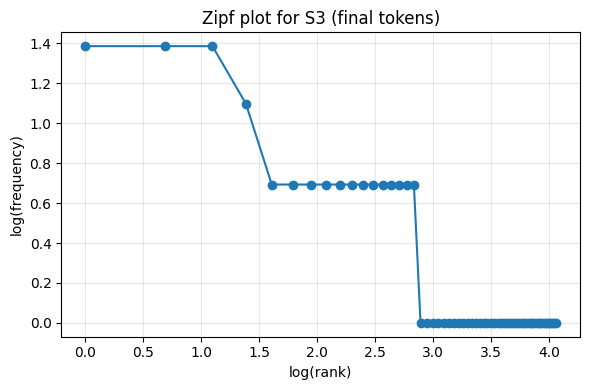

Top 5 bigrams of S1: [(('student', 'portal'), 4), (('the', 'student'), 3), (('.', 'please'), 3), (('keeps', 'asking'), 2), (('asking', 'for'), 2)]
Top 5 bigrams of S3: [(('student', 'portal'), 4), (('keeps', 'asking'), 2), (('asking', 'login'), 2), (("n't", 'know'), 2), (('know', 'changed'), 2)]


In [14]:
import numpy as np, matplotlib.pyplot as plt
from nltk import bigrams

S1 = [t for r in results.values() for t in r["tokens"]]                       # all tokens
S2 = [t for t in S1 if not is_punct(t)]                                         # no punctuation
S3 = [t for r in results.values() for t in r["final"]]                          # final tokens
S4 = [porter.stem(t) for t in S3]                                               # S3 after Porter

stats = pd.DataFrame({
    name: {"Total tokens": len(S), "Unique tokens": len(set(S)), "TTR": round(len(set(S)) / len(S), 4)}
    for name, S in [("S1 (all tokens)", S1), ("S2 (no punctuation)", S2), ("S3 (final tokens)", S3), ("S4 (S3 + Porter)", S4)]
}).T
stats[["Total tokens", "Unique tokens"]] = stats[["Total tokens", "Unique tokens"]].astype(int)
print(stats, "\n")

# ---- top 10 words ----
c1, c3 = Counter(S1), Counter(S3)
print(pd.concat([pd.DataFrame(c1.most_common(10), columns=["S1 word", "S1 freq"]),
                 pd.DataFrame(c3.most_common(10), columns=["S3 word", "S3 freq"])], axis=1).to_string(index=False))

# ---- log(rank) vs log(frequency) for S3 ----
freqs = sorted(c3.values(), reverse=True)
ranks = np.arange(1, len(freqs) + 1)
plt.figure(figsize=(6, 4))
plt.plot(np.log(ranks), np.log(freqs), "o-")
plt.xlabel("log(rank)"); plt.ylabel("log(frequency)"); plt.title("Zipf plot for S3 (final tokens)")
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

# ---- top 5 bigrams (built inside each ticket so no bigram crosses a ticket boundary) ----
def top_bigrams(key, n=5):
    c = Counter(bg for r in results.values() for bg in bigrams(r[key]))
    return c.most_common(n)
print("Top 5 bigrams of S1:", top_bigrams("tokens"))
print("Top 5 bigrams of S3:", top_bigrams("final"))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*
TTR = unique / total tokens: **S1 0.5294, S2 0.5903, S3 0.7073, S4 0.6707**.

- **S1 → S2:** the 26 punctuation tokens are removed. 21 of them are the same "." token, so total tokens fall (170 → 144) much faster than unique tokens (90 → 85) and TTR rises.
- **S2 → S3:** removing 62 stopwords (very repetitive words such as *the* ×13, *i*, *is*, *it*) reduces total tokens a lot (144 → 82) but unique ones only 85 → 58, so TTR rises again.
- **S3 → S4:** Porter stemming does not change the total (82) but merges variants into one type (*open/opening* → `open`, *pc/pcs* → `pc`, *works/worked* → `work`), so unique tokens fall 58 → 55 and TTR falls to 0.6707.

---
## Q6. Interpretation

In [15]:
# Evidence for Q6(b)-(d)
# (b) word_tokenize vs my_tokenize
for s in ["I can't open the student portal before the assignment deadline.", "Dr. Rao's lab PC (No. 14) is down.", "Call me on +91 98765 43210 or 0175-239-3201."]:
    print("(b)", s, "\n    word_tokenize:", word_tokenize(s), "\n    my_tokenize  :", my_tokenize(s))
# (c) stemming results that lose meaning or are not words
print("\n(c)", {w: {"porter": porter.stem(w), "lancaster": lancaster.stem(w), "regexp": regexp.stem(w)} for w in ["portal", "slowly", "running", "changed"]})
# (d) POS-aware lemmatization vs stemming
print("\n(d)", {w: {"POS": tag_votes[w].most_common(1)[0][0], "porter": porter.stem(w), "lemma": lemma.lemmatize(w, wn_pos(tag_votes[w].most_common(1)[0][0]))} for w in ["changed", "reinstalled", "hours", "crashes"]})

(b) I can't open the student portal before the assignment deadline. 
    word_tokenize: ['I', 'ca', "n't", 'open', 'the', 'student', 'portal', 'before', 'the', 'assignment', 'deadline', '.'] 
    my_tokenize  : ['I', "can't", 'open', 'the', 'student', 'portal', 'before', 'the', 'assignment', 'deadline']
(b) Dr. Rao's lab PC (No. 14) is down. 
    word_tokenize: ['Dr.', 'Rao', "'s", 'lab', 'PC', '(', 'No', '.', '14', ')', 'is', 'down', '.'] 
    my_tokenize  : ['Dr', "Rao's", 'lab', 'PC', 'No', '14', 'is', 'down']
(b) Call me on +91 98765 43210 or 0175-239-3201. 
    word_tokenize: ['Call', 'me', 'on', '+91', '98765', '43210', 'or', '0175-239-3201', '.'] 
    my_tokenize  : ['Call', 'me', 'on', '+91 98765 43210', 'or', '0175-239-3201']

(c) {'portal': {'porter': 'portal', 'lancaster': 'port', 'regexp': 'portal'}, 'slowly': {'porter': 'slowli', 'lancaster': 'slow', 'regexp': 'slowly'}, 'running': {'porter': 'run', 'lancaster': 'run', 'regexp': 'runn'}, 'changed': {'porter': 'chang', 'lan

**(a) Why does TTR change from S1 to S4?**
TTR rises from S1 (0.529) to S3 (0.707) because removing punctuation and stopwords deletes the most repeated tokens (21 full stops, 13 *the*), which shrinks the total count much more than the number of unique tokens. It then drops slightly in S4 (0.671) because Porter stemming merges inflected forms (*works/worked*, *open/opening*, *pc/pcs*), reducing the number of unique types while the total stays at 82.

**(b) word_tokenize vs my tokenizer.**
For "I can't open the student portal…" `word_tokenize` returns `ca`, `n't`, while `my_tokenize` returns `can't`. The Treebank tokenizer splits the contraction into pieces, one of which (`ca`) is not a word, while the single token keeps the negation attached to its verb. Another example is the phone number `+91 98765 43210`, which `word_tokenize` splits into three tokens.

**(c) An undesirable stemming result.**
Lancaster stems *portal* (the student portal) to `port`, which is a different word, so a search for "port" would match portal tickets (over-stemming). Porter turns *slowly* into `slowli`, which is not a word, and the Regexp stemmer turns *running* into `runn` and *changed* into `chang`.

**(d) POS-aware lemmatization preserves meaning better.**
In "I don't know what changed", *changed* is tagged `VBD`, so the lemmatizer returns the real verb **change**, while Porter, Lancaster and the Regexp stemmer all give `chang`. Similarly *reinstalled* (VBD) → `reinstall`, whereas Porter and Lancaster give `reinstal`. The lemma is a valid dictionary word that keeps the meaning, while the stem is only a truncated string.